# Team 6: a floor-plan autoencoder for similarity search
AI Methods I, hackathon, Monday

Chloe Hraibeh, Jeff El Khoury, Luca Obejdeanu
IAAC MaAI 2026/27

### Use case
An architect starting a housing project looks for precedents: plans that look like the one on their desk. Our app will let them upload a floor plan and get back the five most similar plans out of 5,000 real homes.

### How
We train a convolutional autoencoder on floor-plan images. The encoder squeezes each plan into a short code, a list of numbers, and plans with a similar layout should get codes close to each other. So "find similar plans" becomes "find the closest codes". Out of the five uses in the class notebook, this is similarity search.

| Section | What happens |
|---|---|
| 0 | setup: libraries, folders, seed |
| 1 | the data: CubiCasa5K, the preprocessing and the split |
| 2 | three setups, trained on the same split and seed |
| 3 | the comparison table and our choice |
| 4 | similarity search: does it find similar plans? |
| 5 | saving the model for the server (ONNX) and checking it |
| 6 | version 2: the same model on cleaned plans, so the search follows the layout and not the drawing style |
| 7 | conclusions and limitations |

# 0. Setup

In [2]:
# Only needed in a new environment: remove the "#" and run once.
%pip install torch torchvision scikit-learn matplotlib umap-learn onnx onnxscript onnxruntime pandas numpy

  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached umap_learn-0.6.0-py3-none-any.whl.metadata (24 kB)
  Using cached onnx-1.23.2-cp312-abi3-win_amd64.whl.metadata (8.7 kB)
  Using cached onnxscript-0.7.2-py3-none-any.whl.metadata (13 kB)
  Using cached onnxruntime-1.32.0-cp314-cp314-win_amd64.whl.metadata (6.1 kB)
  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
  Using cached numpy-2.5.5-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-

In [3]:
import json
import time
import warnings
import zipfile
from pathlib import Path

#hide three harmless warnings that umap prints (progress bars, a future default, parallel jobs)
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="n_jobs value")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import umap

In [4]:
# --- Folders (relative paths: this notebook lives in 01_autoencoder/notebook/) ---
ROOT = Path("..")
DATA_DIR = ROOT / "data"            # ignored by git: the data is never committed
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"         # uploaded to Hugging Face, not to GitHub
MODEL_APP_DIR = ROOT / "model_app"  # what Tuesday's server needs
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, MODEL_APP_DIR / "examples"]:
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)

#CPU on purpose: a GPU would be faster, but the CPU gives exactly the same numbers on every run
DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.15.0+cpu, using device: cpu


# 1. The data

### Dataset card
| | |
|---|---|
| Name | CubiCasa5K |
| Source | [Zenodo 2613548](https://zenodo.org/records/2613548) |
| Content | 5,000 floor-plan images, mostly of Finnish homes, with SVG annotations of walls, rooms, doors and windows. Official split: 4,200 train, 400 validation, 400 test |
| Licence | Dataset: [CC BY-NC 4.0](https://github.com/CubiCasa/CubiCasa5k/blob/master/LICENSE). Our code is MIT |
| Cite | Kalervo, A. et al. (2019), CubiCasa5K: A Dataset and an Improved Multi-Task Model for Floorplan Image Analysis, SCIA |
| We use | only the images (`F1_scaled.png`, the first floor of each home). An autoencoder needs no labels, so we don't use the annotations |

### Preprocessing, and why
1. Greyscale: the colour says almost nothing about the layout.
2. Invert: the plans are dark lines on white paper. After inverting, the walls are bright (1) and the background is dark (0), like the clothes in the class notebook. Otherwise most of the error would be about the empty white paper.
3. Pad to a square, then resize to 128 x 128 px. With the padding a long, narrow plan stays long and narrow instead of getting squashed.
4. Pixels between 0 and 1 (divided by 255).

The server on Tuesday has to do exactly the same steps, so they also go into the config file in section 5.

In [5]:
IMAGE_SIZE = 128


def preprocess_plan(image):
    # PIL image -> 128x128 numpy array, walls bright (1), background dark (0)
    grey = ImageOps.grayscale(image)
    inverted = ImageOps.invert(grey)
    side = max(inverted.size)
    square = Image.new("L", (side, side), 0)                     # black square = empty paper after inverting
    square.paste(inverted, ((side - inverted.width) // 2, (side - inverted.height) // 2))
    small = square.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    return np.asarray(small, dtype=np.uint8)

The download is one 5.5 GB zip. The notebook reads the plans straight from the zip, without unzipping it, and saves the small 128 px versions in one file, `cubicasa5k_128.npz` (27 MB). This only runs once. After that the notebook loads the small file in a second, and if you already have it in `data/` you don't need the zip at all.

In [7]:
ZIP_PATH = DATA_DIR / "cubicasa5k.zip"
NPZ_PATH = DATA_DIR / f"cubicasa5k_{IMAGE_SIZE}.npz"

if not NPZ_PATH.exists():
    # Download first if needed (5.5 GB):  https://zenodo.org/records/2613548/files/cubicasa5k.zip?download=1
    with zipfile.ZipFile(ZIP_PATH) as zf:
        names = set(zf.namelist())
        arrays, ids, splits = [], [], []
        for split in ["train", "val", "test"]:
            listing = [n for n in names if n.endswith(f"/{split}.txt")][0]
            folders = zf.read(listing).decode().split()
            for folder in folders:                                  # e.g. /high_quality_architectural/2003/
                image_name = next(n for n in (f"cubicasa5k{folder}F1_scaled.png", f"cubicasa5k{folder}F1_original.png")
                                  if n in names)
                with zf.open(image_name) as f:
                    arrays.append(preprocess_plan(Image.open(f)))
                ids.append(folder.strip("/"))
                splits.append(split)
            print(f"{split}: {splits.count(split)} plans")
    np.savez_compressed(NPZ_PATH, images=np.stack(arrays), ids=np.array(ids), splits=np.array(splits))
    print(f"saved {NPZ_PATH}")

c:\Users\Chloe\hackathon-team6-cubicasa\.venv\Lib\site-packages\PIL\Image.py:3593: DecompressionBombWarning: Image size (90344064 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


train: 4200 plans
val: 400 plans
test: 400 plans
saved ..\data\cubicasa5k_128.npz


### Split first
We use the official train, validation and test split of the dataset, and we fix it before anything else. The test plans are only used at the end, once, to score each setup. With the official split our numbers can also be compared with other work on CubiCasa5K.

In [8]:
data = np.load(NPZ_PATH)
images, plan_ids, plan_splits = data["images"], data["ids"], data["splits"]

# uint8 0-255 -> float 0-1, shape (N, 1, 128, 128): (plans, channels, height, width)
X_all = torch.from_numpy(images).float().div(255).unsqueeze(1)
X_train = X_all[plan_splits == "train"]
X_val = X_all[plan_splits == "val"]
X_test = X_all[plan_splits == "test"]
ids_test = plan_ids[plan_splits == "test"]
style_test = np.array([i.split("/")[0] for i in ids_test])   # drawing style: high_quality, high_quality_architectural or colorful

print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape), "| test", tuple(X_test.shape))
print(f"share of bright (wall/line) pixels: {X_train.mean():.3f}")

train (4200, 1, 128, 128) | validation (400, 1, 128, 128) | test (400, 1, 128, 128)
share of bright (wall/line) pixels: 0.065


Figure saved to ..\figures\01_samples.png


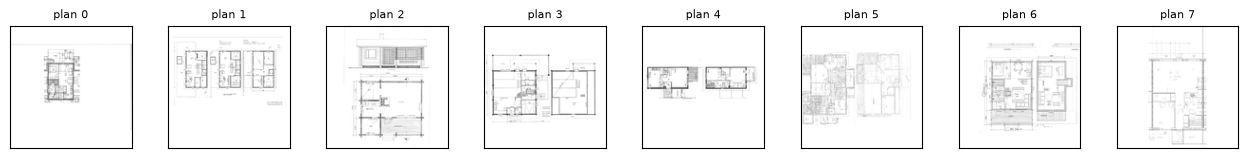

In [9]:
def show_images(rows, titles=None, row_labels=None, size=1.6):
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(1 - batch[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)   # 1 - x: show as dark lines on white
            ax.set_xticks([]); ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(titles[c], fontsize=8)
        if row_labels is not None:
            axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    plt.tight_layout()


show_images([X_train[:8]], titles=[f"plan {i}" for i in range(8)])
save_fig("01_samples")
plt.show()

# 2. Three setups
We compare three autoencoders. Everything else is the same: the split, the seed, the number of epochs and the training loop.

| Setup | Architecture | Code size | Why we try it |
|---|---|---|---|
| A | dense | 64 | the simplest one, like section 2 of the class notebook |
| B | convolutional | 32 | convolutions keep the 2D structure of walls and rooms, and a small code compresses more |
| C | convolutional | 128 | the same network with a bigger code: more detail, but does it still group similar plans? |

The class notebook showed that on bigger images convolutional models win clearly. At 128 px a dense layer connects all 16,384 pixels to every neuron, so we expect A to be big and weaker.

In [10]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        n = IMAGE_SIZE * IMAGE_SIZE                     # 16,384 pixels
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),                 # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, n), nn.Sigmoid(),
            nn.Unflatten(1, (1, IMAGE_SIZE, IMAGE_SIZE)),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvAE(nn.Module):
    # 128 -> 64 -> 32 -> 16 -> 8, then a linear layer makes the code. The decoder mirrors it.
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),    # 128 -> 64
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),   # 64 -> 32
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),   # 32 -> 16
            nn.Conv2d(64, 64, 3, stride=2, padding=1), nn.ReLU(),   # 16 -> 8
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 64, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 16 -> 32
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 32 -> 64
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 64 -> 128
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

The training loop is the one from the class notebook: the target is the input itself. We also time each setup.

We changed one thing from the class notebook: the loss. Our first runs used MSE, like in class, and in two separate tries several setups got stuck drawing a blank page (the codes of 8 and 32 in one, two of these three setups in the other). Only 6.5% of the pixels in a plan are lines, so a blank page is already 95% right, and once the sigmoid at the end gives almost 0 everywhere its gradient nearly disappears and the network stops learning. Binary cross-entropy (BCE), the loss the class notebook uses for its VAE, doesn't have this problem: it keeps pushing on every line pixel the model misses. So we train with BCE, but we still report the MSE, to compare with the class notebook.

In [11]:
def train_autoencoder(model, X_train, X_val, epochs=15, lr=1e-3, batch_size=64, verbose=True):
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            loss = nn.functional.binary_cross_entropy(model(batch), batch)   # target = input (BCE: see above)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        val_mse = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_mse})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.4f}  validation MSE {val_mse:.4f}")
    seconds = time.time() - start
    print(f"trained in {seconds:.0f} s")
    return model, pd.DataFrame(history), seconds


@torch.no_grad()
def reconstruct(model, X, batch_size=200):
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


@torch.no_grad()
def reconstruction_error(model, X, batch_size=200):
    # One number per plan: the mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(DEVICE)
        errors.append(((model(batch) - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


@torch.no_grad()
def encode(model, X, batch_size=200):
    model.eval()
    return torch.cat([model.encoder(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


def n_params(model):
    return sum(p.numel() for p in model.parameters())

In [12]:
EPOCHS = 20
setups = {
    "A (dense, code 64)": lambda: DenseAE(latent_dim=64),
    "B (conv, code 32)": lambda: ConvAE(latent_dim=32),
    "C (conv, code 128)": lambda: ConvAE(latent_dim=128),
}
models, histories, times = {}, {}, {}
for name, make in setups.items():
    print(f"--- {name}")
    models[name], histories[name], times[name] = train_autoencoder(make(), X_train, X_val, epochs=EPOCHS, verbose=False)

--- A (dense, code 64)
trained in 33 s
--- B (conv, code 32)
trained in 78 s
--- C (conv, code 128)
trained in 83 s


Figure saved to ..\figures\02_training_curves.png


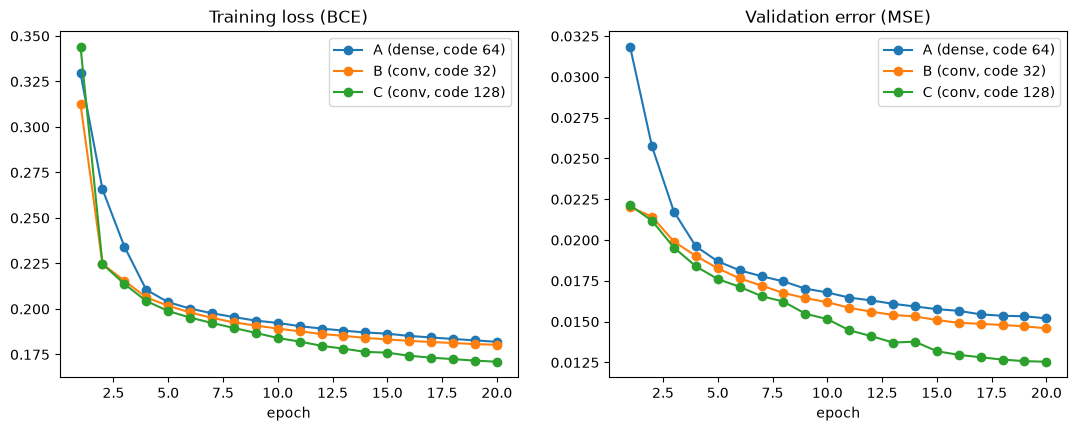

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in histories.items():
    ax1.plot(hist["epoch"], hist["train_loss"], marker="o", label=name)
    ax2.plot(hist["epoch"], hist["val_mse"], marker="o", label=name)
ax1.set_title("Training loss (BCE)"); ax2.set_title("Validation error (MSE)")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.legend()
save_fig("02_training_curves")
plt.show()

All the curves are still going down at epoch 20, for training and for validation, so none of the setups overfits yet and more epochs would probably help a bit. C ends with the lowest validation error (0.0123), and A starts much higher and stays the worst.

# 3. Comparison table
The reconstruction error alone doesn't tell us if the codes are good for our use, finding similar plans. So we add a second measure.

Retrieval test (top-1): for every test plan we make a slightly changed copy, shifted by 3 pixels and with a bit of noise, like the same plan scanned again. We encode the copy and look for its closest code among the 400 test plans. If the closest one is the original, the search found it. A code that's good for similarity search should find the original almost every time.

In [14]:
def perturb(X, shift=3, noise=0.05, seed=RANDOM_STATE):
    # A slightly changed copy of each plan: shifted a few pixels and with light noise
    g = torch.Generator().manual_seed(seed)
    shifted = torch.roll(X, shifts=(shift, -shift), dims=(2, 3))
    return (shifted + noise * torch.randn(shifted.shape, generator=g)).clamp(0, 1)


def retrieval_top1(model, X):
    codes = encode(model, X)
    query_codes = encode(model, perturb(X))
    nearest = torch.cdist(query_codes, codes).argmin(dim=1)
    return (nearest == torch.arange(len(X))).float().mean().item()


rows = []
for name, model in models.items():
    rows.append({
        "setup": name,
        "parameters": n_params(model),
        "train time (s)": round(times[name]),
        "validation MSE": histories[name]["val_mse"].iloc[-1],
        "test MSE": reconstruction_error(model, X_test).mean().item(),
        "retrieval top-1 (test)": retrieval_top1(model, X_test),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(FIG_DIR / "03_comparison_table.csv", index=False)
comparison

,setup,parameters,train time (s),validation MSE,test MSE,retrieval top-1 (test)
0,"A (dense, code 64)",8438336,33,0.0152,0.0160,0.1950
1,"B (conv, code 32)",386657,78,0.0146,0.0152,0.4175
2,"C (conv, code 128)",1173185,83,0.0125,0.0132,0.7125


Figure saved to ..\figures\03_reconstructions.png


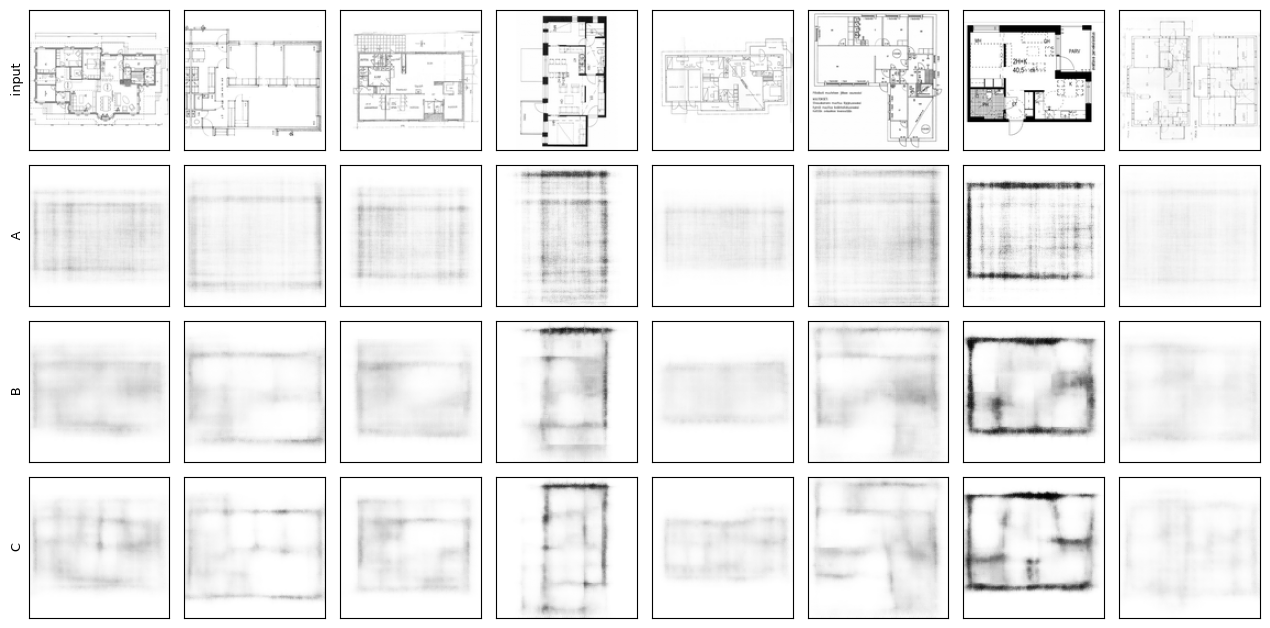

In [15]:
sample = X_test[:8]
show_images([sample] + [reconstruct(m, sample) for m in models.values()],
            row_labels=["input"] + [n.split(" (")[0] for n in models])
save_fig("03_reconstructions")
plt.show()

The reconstructions show the difference better than the numbers. A gives a grid-like blur: a dense layer treats every pixel on its own and doesn't see lines. B keeps the outline of the plan but turns the inside into blobs. C keeps the outline and the main inner walls, especially on plans drawn with thick walls. None of them keeps doors, furniture or text: at 128 px those are almost gone already.

### What we conclude

| | A (dense, 64) | B (conv, 32) | C (conv, 128) |
|---|---|---|---|
| Parameters | 8.4 M | 0.39 M | 1.17 M |
| Test MSE | 0.0162 | 0.0153 | 0.0131 |
| Retrieval top-1 | 21% | 47% | 69% |

- Convolutional is clearly better than dense at 128 px, as the class notebook said. A has 22 times more parameters than B and still rebuilds worse.
- The bigger code helps. From 32 to 128 numbers the test error drops by 14% and the retrieval goes from 47% to 69%. A floor plan holds much more than a T-shirt, so 32 numbers aren't enough to tell 5,000 plans apart.
- For our app the retrieval matters more than the MSE. The errors are all between 0.013 and 0.016, but the retrieval goes from 21% to 69%: a model can rebuild the average pixels quite well and still give codes that can't tell plans apart.
- We keep C. It has the best reconstruction and the best retrieval, and with 1.2 million parameters (a 4.5 MB ONNX file) it fits on a free server.

### Is the autoencoder worth it?
A fair question before keeping a neural network: would something simpler find the plans just as well? We run the same retrieval test with two simpler ways of comparing plans:
- the raw pixels: the 16,384 numbers of the image, compared directly;
- PCA with 128 components (Day 3), the same length as our code, fitted on the training plans.

PCA keeps 58% of the variance of the pixels
Figure saved to ..\figures\05_baselines.png


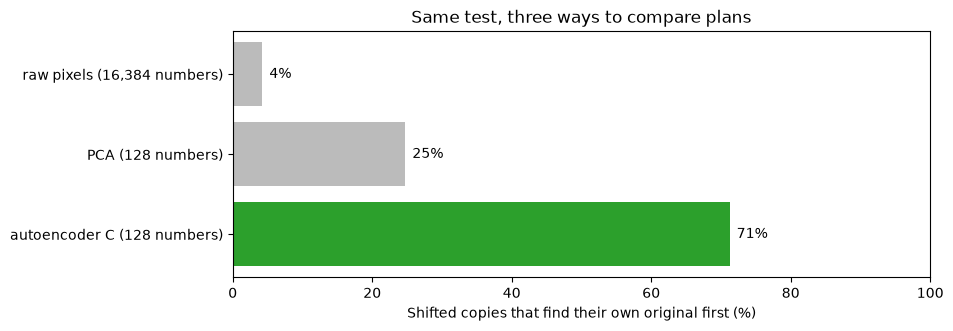

,method,retrieval top-1 (test)
0,"raw pixels (16,384 numbers)",0.0425
1,PCA (128 numbers),0.2475
2,autoencoder C (128 numbers),0.7125


In [16]:
#the same shifted copies, compared in two simpler ways: the raw pixels, and PCA with as many numbers as our code
from sklearn.decomposition import PCA


def retrieval_from_codes(codes, query_codes):
    #share of shifted copies whose closest code is the code of their own original
    nearest = torch.cdist(query_codes, codes).argmin(dim=1)
    return (nearest == torch.arange(len(codes))).float().mean().item()


X_test_shifted = perturb(X_test)
pixel_score = retrieval_from_codes(X_test.flatten(1), X_test_shifted.flatten(1))

pca = PCA(n_components=128, random_state=RANDOM_STATE)
pca.fit(X_train.flatten(1).numpy())
pca_codes = torch.from_numpy(pca.transform(X_test.flatten(1).numpy()))
pca_queries = torch.from_numpy(pca.transform(X_test_shifted.flatten(1).numpy()))
pca_score = retrieval_from_codes(pca_codes, pca_queries)
print(f"PCA keeps {pca.explained_variance_ratio_.sum():.0%} of the variance of the pixels")

ae_score = comparison.set_index("setup").loc["C (conv, code 128)", "retrieval top-1 (test)"]
baselines = pd.DataFrame({"method": ["raw pixels (16,384 numbers)", "PCA (128 numbers)", "autoencoder C (128 numbers)"],
                          "retrieval top-1 (test)": [pixel_score, pca_score, ae_score]})

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(baselines["method"], baselines["retrieval top-1 (test)"] * 100, color=["#bbbbbb", "#bbbbbb", "#2ca02c"])
for i, value in enumerate(baselines["retrieval top-1 (test)"]):
    ax.text(value * 100 + 1, i, f"{value:.0%}", va="center")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Shifted copies that find their own original first (%)")
ax.set_title("Same test, three ways to compare plans")
save_fig("05_baselines")
plt.show()
baselines

Comparing the raw pixels almost never works (4%): a shift of 3 pixels moves every line onto other pixels, so the copy looks like a different plan. PCA with 128 numbers does better (25%), but it's a straight-line compression that keeps only 58% of the variance. The autoencoder gets 69% with the same 128 numbers, because it learned codes that hardly change with a small shift, which is what a search needs. So here the neural network is worth it, unlike on Day 4, where our network only tied with the random forest.

### And the reconstruction error?
On their own the MSE values (0.0131 for C) are hard to read. Two dumb ways of "rebuilding" a plan give them a scale: a blank page, which is what the first MSE runs drew, and the average plan of the training set.

In [17]:
#two dumb reconstructions: a blank page (0 everywhere after inverting) and the average training plan
blank_mse = (X_test ** 2).mean().item()
average_plan = X_train.mean(dim=0, keepdim=True)
average_mse = ((X_test - average_plan) ** 2).mean().item()
c_mse = comparison.set_index("setup").loc["C (conv, code 128)", "test MSE"]

print(f"C is {1 - c_mse / blank_mse:.0%} below the blank page and {1 - c_mse / average_mse:.0%} below the average plan")
pd.DataFrame({"reconstruction": ["blank page", "average training plan", "autoencoder C"],
              "test MSE": [blank_mse, average_mse, c_mse]})

C is 56% below the blank page and 45% below the average plan


,reconstruction,test MSE
0,blank page,0.0300
1,average training plan,0.0243
2,autoencoder C,0.0132


A blank page already gets an MSE of 0.0300 and the average plan 0.0243, because most of every page is empty background. C gets 0.0131: 57% below the blank page and 46% below the average plan. So the small MSE numbers do mean that the model rebuilds the plans, they only look small because the lines are just 6.5% of the pixels.

### Testing batch normalization and weight initialization

We compare four versions of the convolutional autoencoder:

1. Original model.
2. Explicit weight initialization.
3. Batch normalization.
4. Both changes.

All versions use a code size of 128, the same data split, BCE loss,
learning rate, batch size and 20 training epochs.

We compare validation reconstruction error, visual reconstructions,
and validation retrieval before choosing a model.

In [18]:
class ConvAEWithBN(ConvAE):
    def __init__(self, latent_dim=128):
        super().__init__(latent_dim=latent_dim)

        # Encoder: insert normalization after each convolution.
        encoder_layers = []

        for layer in self.encoder:
            encoder_layers.append(layer)

            if isinstance(layer, nn.Conv2d):
                encoder_layers.append(
                    nn.BatchNorm2d(layer.out_channels)
                )

        self.encoder = nn.Sequential(*encoder_layers)

        # Decoder: normalize hidden feature maps.
        # Leave the final image-producing layer unchanged.
        decoder_layers = []

        for layer in self.decoder:
            decoder_layers.append(layer)

            if (
                isinstance(layer, nn.ConvTranspose2d)
                and layer.out_channels != 1
            ):
                decoder_layers.append(
                    nn.BatchNorm2d(layer.out_channels)
                )

        self.decoder = nn.Sequential(*decoder_layers)

In [19]:
def initialize_autoencoder(model):
    for layer in model.modules():

        # Hidden layers use ReLU:
        # choose Kaiming initialization.
        if isinstance(
            layer,
            (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)
        ):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_in",
                nonlinearity="relu"
            )

            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

        # Start batch normalization with scale 1 and offset 0.
        elif isinstance(layer, nn.BatchNorm2d):
            nn.init.ones_(layer.weight)
            nn.init.zeros_(layer.bias)

    # These two layers are not followed by ReLU:
    # use Xavier initialization instead.
    nn.init.xavier_uniform_(model.encoder[-1].weight)
    nn.init.xavier_uniform_(model.decoder[-2].weight)

In [20]:
experiment_settings = {
    "Original": (False, False),
    "Initialization only": (False, True),
    "Batch normalization only": (True, False),
    "Both": (True, True),
}

experiment_models = {}
experiment_histories = {}
experiment_times = {}

for name, (use_bn, use_initialization) in experiment_settings.items():
    print(f"\n--- {name} ---")

    # Reset the seed before creating each model.
    torch.manual_seed(RANDOM_STATE)

    if use_bn:
        candidate = ConvAEWithBN(latent_dim=128)
    else:
        candidate = ConvAE(latent_dim=128)

    # Apply initialization once, before training.
    if use_initialization:
        initialize_autoencoder(candidate)

    trained, history, seconds = train_autoencoder(
        candidate,
        X_train,
        X_val,
        epochs=20,
        lr=0.001,
        batch_size=64,
        verbose=True
    )

    experiment_models[name] = trained
    experiment_histories[name] = history
    experiment_times[name] = seconds


--- Original ---
epoch  1  train loss 0.3291  validation MSE 0.0226
epoch  2  train loss 0.2265  validation MSE 0.0218
epoch  3  train loss 0.2208  validation MSE 0.0204
epoch  4  train loss 0.2082  validation MSE 0.0189
epoch  5  train loss 0.2007  validation MSE 0.0179
epoch  6  train loss 0.1968  validation MSE 0.0174
epoch  7  train loss 0.1932  validation MSE 0.0167
epoch  8  train loss 0.1904  validation MSE 0.0162
epoch  9  train loss 0.1874  validation MSE 0.0155
epoch 10  train loss 0.1850  validation MSE 0.0151
epoch 11  train loss 0.1826  validation MSE 0.0147
epoch 12  train loss 0.1803  validation MSE 0.0142
epoch 13  train loss 0.1784  validation MSE 0.0138
epoch 14  train loss 0.1769  validation MSE 0.0136
epoch 15  train loss 0.1757  validation MSE 0.0134
epoch 16  train loss 0.1744  validation MSE 0.0131
epoch 17  train loss 0.1734  validation MSE 0.0129
epoch 18  train loss 0.1726  validation MSE 0.0128
epoch 19  train loss 0.1716  validation MSE 0.0126
epoch 20  tra

***Combining batch normalization with explicit initialization reduced validation reconstruction error by about 17% compared with our baseline in this run. We’re now checking whether that improvement also produces clearer plans and better similarity retrieval.***


Figure saved to ..\figures\batchnorm_initialization_training.png


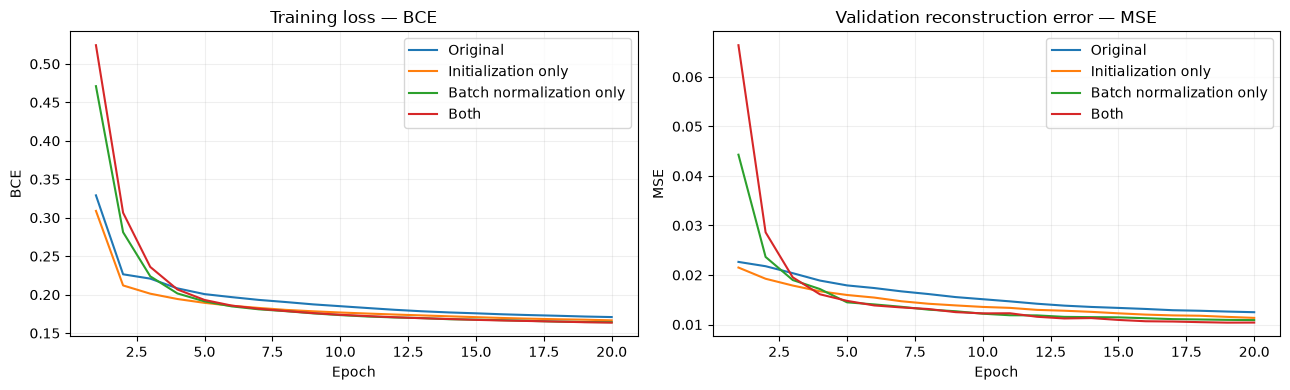

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in experiment_histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_mse"],
        label=name
    )

axes[0].set_title("Training loss — BCE")
axes[1].set_title("Validation reconstruction error — MSE")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)

axes[0].set_ylabel("BCE")
axes[1].set_ylabel("MSE")

plt.tight_layout()
save_fig("batchnorm_initialization_training")
plt.show()

### Results: batch normalization and weight initialization

We compared four versions of the convolutional autoencoder, keeping
the latent size at 128, the BCE training loss, learning rate of 0.001,
batch size of 64, and training budget of 20 epochs.

| Configuration | Final validation MSE ↓ | Reduction versus original |
|---|---:|---:|
| Original | 0.0125 | — |
| Initialization only | 0.0113 | 9.6% |
| Batch normalization only | 0.0109 | 12.8% |
| Both | **0.0104** | **16.8%** |

Percentages are calculated from the rounded values shown above.

### Reading the graphs

The left graph shows training loss measured with binary cross-entropy
(BCE). Explicit initialization improved early learning. The models
with batch normalization started with higher losses but improved
rapidly and finished below the original model.

The right graph shows reconstruction error on unseen validation
images, measured with mean squared error (MSE). Combining batch
normalization and initialization achieved the lowest final error:
approximately 17% below the original model.

Training and validation generally improved throughout the run.
There was no sustained increase in validation error suggesting
overfitting within these 20 epochs. BCE and MSE have different scales,
so their numerical values should not be compared directly.

### Conclusion and next checks

Both changes together gave the best validation reconstruction result
in this single-seed experiment. This does not yet establish clearer
architectural details or better similarity search.

We will inspect the reconstructed plans and compare validation
retrieval before choosing the model for the application.

Figure saved to ..\figures\batchnorm_initialization_reconstructions.png


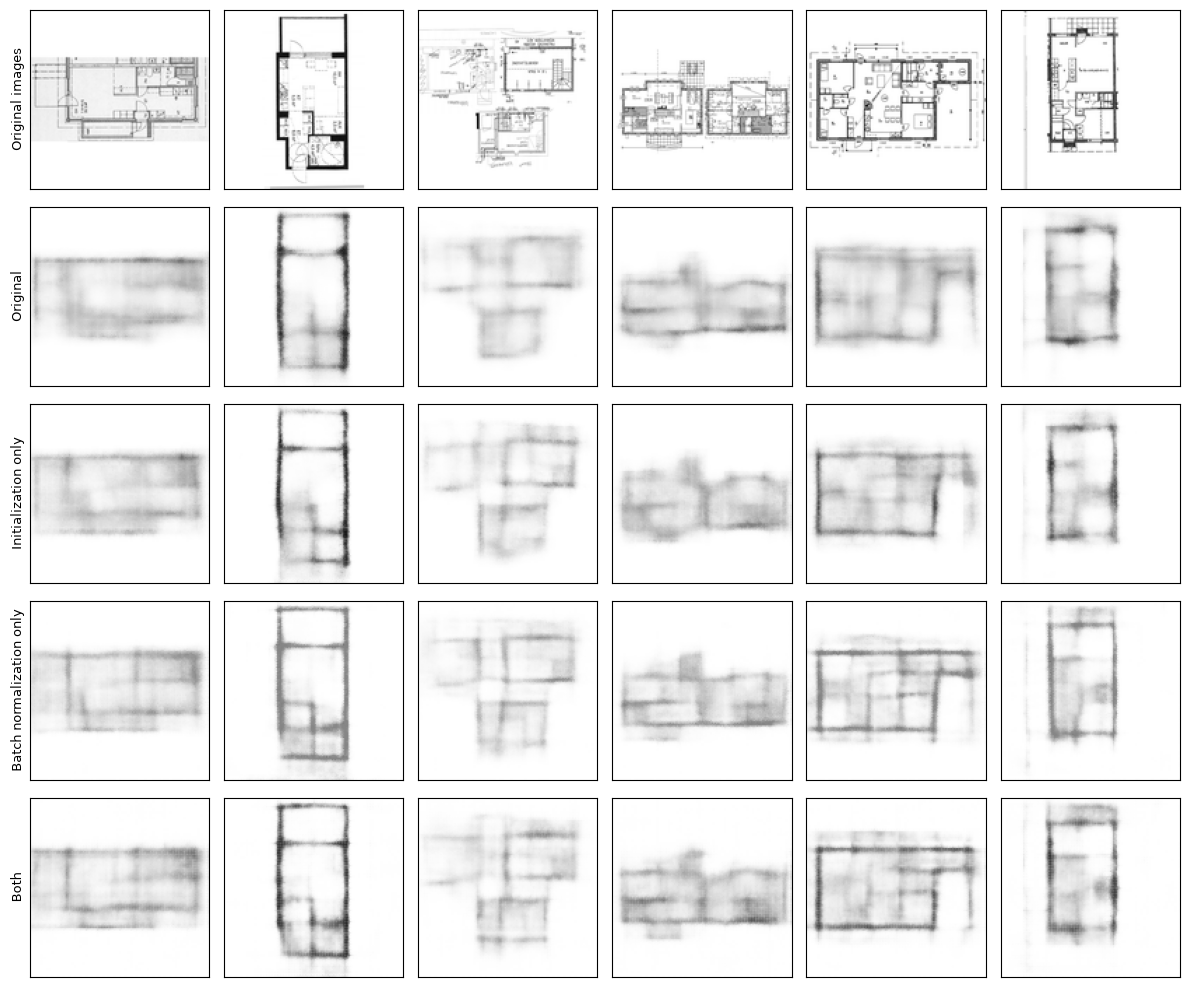

In [22]:
sample = X_val[:6]

image_rows = [sample]
row_labels = ["Original images"]

for name, model in experiment_models.items():
    image_rows.append(
        reconstruct(model, sample)
    )
    row_labels.append(name)

show_images(
    image_rows,
    row_labels=row_labels,
    size=2
)

save_fig("batchnorm_initialization_reconstructions")
plt.show()

### Visual comparison of reconstructions

Each column shows the same validation plan reconstructed by all four
model configurations.

The original model captures broad footprints but produces blurred
boundaries. Explicit initialization strengthens some outlines.
Batch normalization makes several internal divisions more distinct,
particularly in examples 1, 3 and 5.

Combining both changes improves visible structure over the original
in several examples and achieves the lowest overall validation MSE.
However, it is not visibly superior in every example.

All configurations still lose fine architectural details, including
doors, furniture, text and thin walls. Some reconstructed divisions
do not match the originals.

These six examples provide qualitative support for improved
reconstruction. They do not establish better similarity retrieval,
which we evaluate separately.

In [23]:
experiment_rows = []

for name, model in experiment_models.items():
    experiment_rows.append({
        "model": name,
        "validation_MSE": reconstruction_error(
            model, X_val
        ).mean().item(),
        "validation_retrieval_top1": retrieval_top1(
            model, X_val
        ),
        "training_seconds": experiment_times[name]
    })

experiment_comparison = pd.DataFrame(experiment_rows)

display(experiment_comparison)

experiment_comparison.to_csv(
    FIG_DIR / "batchnorm_initialization_comparison.csv",
    index=False
)

,model,validation_MSE,validation_retrieval_top1,training_seconds
0,Original,0.0125,0.7375,79.9139
1,Initialization only,0.0113,0.3300,84.6942
2,Batch normalization only,0.0109,0.4550,111.0402
3,Both,0.0104,0.6550,110.8732


### Reconstruction improved, but retrieval did not

Combining batch normalization and explicit weight initialization
achieved the lowest validation reconstruction MSE: 0.0104,
compared with 0.0125 for the original model.

However, the original model (autoencoder - before batch normalization) achieved the highest validation
retrieval top-1 score: 73.75%, compared with 65.50% for both
changes, 45.50% for batch normalization alone, and 33.00%
for initialization alone.

This demonstrates that better pixel reconstruction does not
necessarily produce latent codes better suited to Euclidean
similarity search.

We retain the original model for the similarity-search prototype
based on this validation benchmark. These results come from one
training seed and a specific shifted-and-noisy original-recovery
test; they do not measure architectural relevance directly.

# 4. Similarity search: does it work?
We take C, encode all 5,000 plans once (our collection), and for four test plans we show the five closest plans in the collection. That's exactly what the app will do: encode the uploaded plan, then look for the closest stored codes.

chosen model: C (conv, code 128)


collection codes: (5000, 128)
query 0: distances 30.58-35.57
query 50: distances 51.07-52.35
query 120: distances 63.49-68.11
query 250: distances 32.34-35.74
for comparison, the median distance between two random plans is 92.23


Figure saved to ../figures/04_similarity_search.png


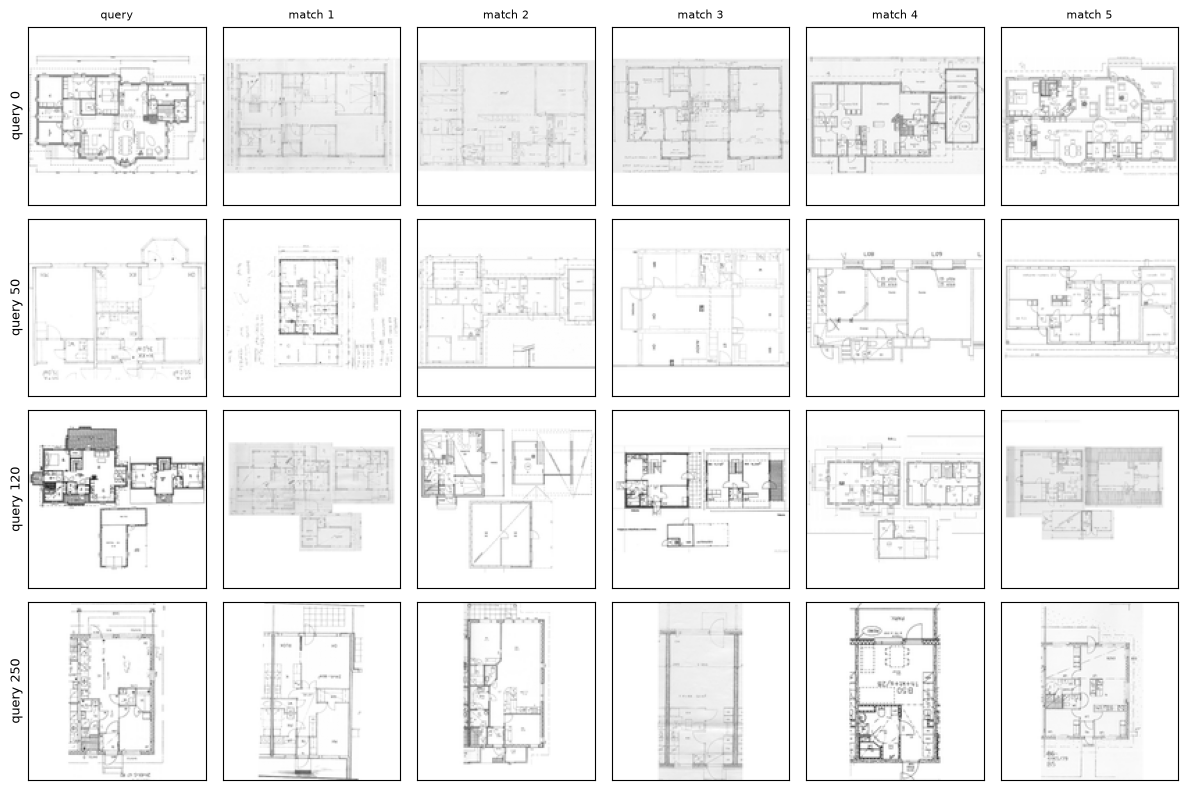

In [16]:
best_name = comparison.sort_values("retrieval top-1 (test)", ascending=False).iloc[0]["setup"]
best = models[best_name]
print("chosen model:", best_name)

codes_all = encode(best, X_all)          # one code per plan, for the whole collection
codes_test = encode(best, X_test)
print("collection codes:", tuple(codes_all.shape))


def most_similar(query_code, codes, k=5, exclude=None):
    distances = torch.cdist(query_code.unsqueeze(0), codes).squeeze(0)
    if exclude is not None:
        distances[exclude] = float("inf")       # do not return the query plan itself
    best_k = distances.topk(k, largest=False)
    return best_k.indices, best_k.values


test_positions = np.where(plan_splits == "test")[0]
rows, labels = [], []
for q in [0, 50, 120, 250]:
    query_index = test_positions[q]
    idx, dists = most_similar(codes_all[query_index], codes_all, exclude=query_index)
    rows.append(torch.cat([X_all[query_index:query_index + 1], X_all[idx]]))
    labels.append(f"query {q}")
    print(f"query {q}: distances {dists.min():.2f}-{dists.max():.2f}")
typical = torch.cdist(codes_test[:200], codes_test[:200]).median()
print(f"for comparison, the median distance between two random plans is {typical:.2f}")

show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 6)], size=2.0)
save_fig("04_similarity_search")
plt.show()

- The matches have the same overall footprint and proportions as the query. The narrow plan (query 250) finds narrow plans, the plan made of three separate buildings (query 120) finds other plans made of two or three volumes, and the wide plan with a bay window (query 0) finds wide plans, one of them with a similar bay window.
- The distances say the same. The matches are at about 31 to 68 from their query, against 92 between two random plans: about 3 times closer for queries 0 and 250, and only 1.4 times for query 120, the most unusual plan.
- It doesn't match the room programme. It compares the shape and how much is drawn, not "three bedrooms and an open kitchen". The way the plan is drawn also counts: three of the five matches of query 0 are pale, faded scans, and the first match of query 50 is a small square plan full of text, nothing like the query.

Figure saved to ../figures/04_latent_umap.png


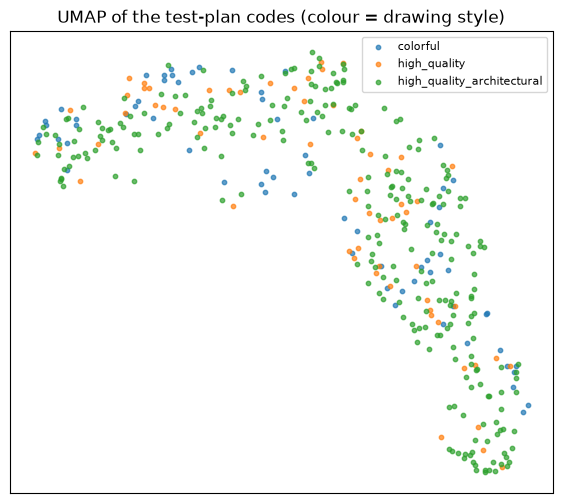

In [17]:
# The latent space in 2D (UMAP, as on Day 3). Colours = drawing style, which the model never saw.
embedding = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_test.numpy())
fig, ax = plt.subplots(figsize=(7, 6))
for style in np.unique(style_test):
    mask = style_test == style
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=10, alpha=0.7, label=style)
ax.set_title("UMAP of the test-plan codes (colour = drawing style)")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8)
save_fig("04_latent_umap")
plt.show()

On the UMAP map the test plans form one long band, not separate groups: floor plans change gradually from one to the next. The three subsets of CubiCasa5K (`colorful`, `high_quality` and `high_quality_architectural`), which the model never saw, are mixed along the band, so the codes aren't just sorting the plans by subset. As always with UMAP, the distances on the map don't mean much.

### Where does the search fail?
31% of the shifted copies don't find their original. To see which plans they are, we split the test plans into four quarters by how much is drawn on them (the share of bright line pixels after the preprocessing), and we also look at the three subsets of CubiCasa5K.

Figure saved to ../figures/06_failures_by_ink.png


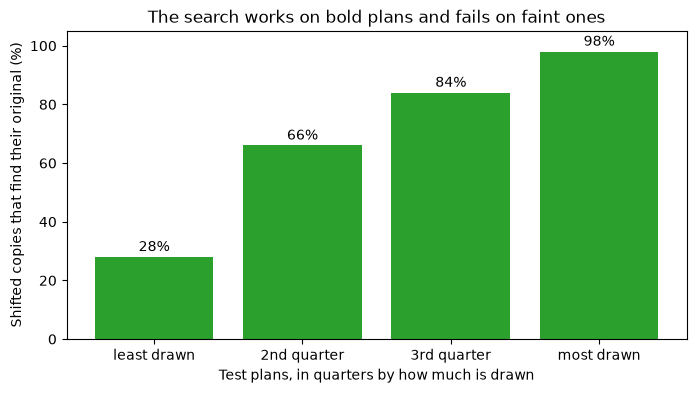

share of line pixels: 0.081 in the plans it finds, 0.043 in the ones it misses


,plans,retrieval top-1
colorful,67,0.9104
high_quality,63,0.6508
high_quality_architectural,270,0.6444


In [18]:
#for every test plan: does its shifted copy find it? Then by how much is drawn, and by subset
found = (torch.cdist(encode(best, X_test_shifted), codes_test).argmin(dim=1) == torch.arange(len(X_test))).numpy()
ink = X_test.mean(dim=(1, 2, 3)).numpy()
ink_quarter = pd.qcut(ink, 4, labels=["least drawn", "2nd quarter", "3rd quarter", "most drawn"])

by_ink = pd.Series(found).groupby(ink_quarter, observed=True).mean()
by_subset = pd.DataFrame({"plans": pd.Series(style_test).value_counts().sort_index(),
                          "retrieval top-1": pd.Series(found).groupby(style_test).mean()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_ink.index.astype(str), by_ink.values * 100, color="#2ca02c")
for i, value in enumerate(by_ink.values):
    ax.text(i, value * 100 + 2, f"{value:.0%}", ha="center")
ax.set_ylim(0, 105)
ax.set_ylabel("Shifted copies that find their original (%)")
ax.set_xlabel("Test plans, in quarters by how much is drawn")
ax.set_title("The search works on bold plans and fails on faint ones")
save_fig("06_failures_by_ink")
plt.show()

print(f"share of line pixels: {ink[found].mean():.3f} in the plans it finds, {ink[~found].mean():.3f} in the ones it misses")
by_subset

The search depends a lot on how much is drawn. On the quarter of plans with the fewest lines only 28% of the copies find their original, on the quarter with the most lines 98%. The plans it misses have about half as many line pixels (0.043 against 0.081). A faint scan gives the encoder little to hold on to, and the noise of the shifted copy covers most of what's there. By subset, the `colorful` plans are found 91% of the time and the other two about 65%. For the app this means the best matches will come for clear, bold plans, and a contrast step in the preprocessing is a natural thing to try next.

### The plans it misses
Six of the test plans whose shifted copy doesn't find them, with what the search returned instead.

Figure saved to ../figures/07_failure_gallery.png


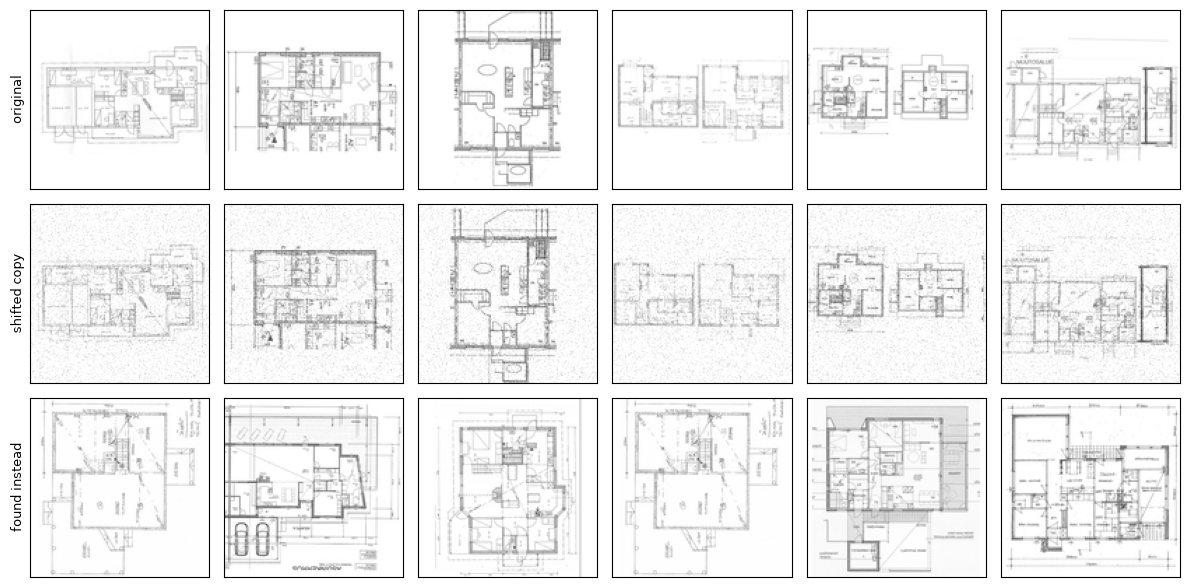

In [19]:
#the first six misses: the original, the shifted copy we searched with, and the plan the search returned instead
missed = np.where(~found)[0][:6]
found_instead = torch.cdist(encode(best, X_test_shifted[missed]), codes_test).argmin(dim=1)
show_images([X_test[missed], X_test_shifted[missed], X_test[found_instead]],
            row_labels=["original", "shifted copy", "found instead"], size=2.0)
save_fig("07_failure_gallery")
plt.show()

Most of the misses are faint drawings (the first, fourth and sixth), where the noise of the shifted copy is almost as strong as the lines. Two different misses (the first and the fourth) even return the same faint plan with big rooms crossed by diagonal lines: a plan that sits close to many faint plans. The plans found instead still have a similar footprint and density, so for an architect they aren't useless matches. The test only counts the exact original as a success.

### An atlas of the 5,000 plans
To see how the model organises all the plans at once, we put the 5,000 codes on a 2D map with UMAP and draw the plans themselves instead of dots. The map is cut into a grid, and every cell shows the plan closest to its centre. Plans that are neighbours on the map have close codes, so they are the ones the app would show together.

Figure saved to ../figures/08_plan_atlas.png


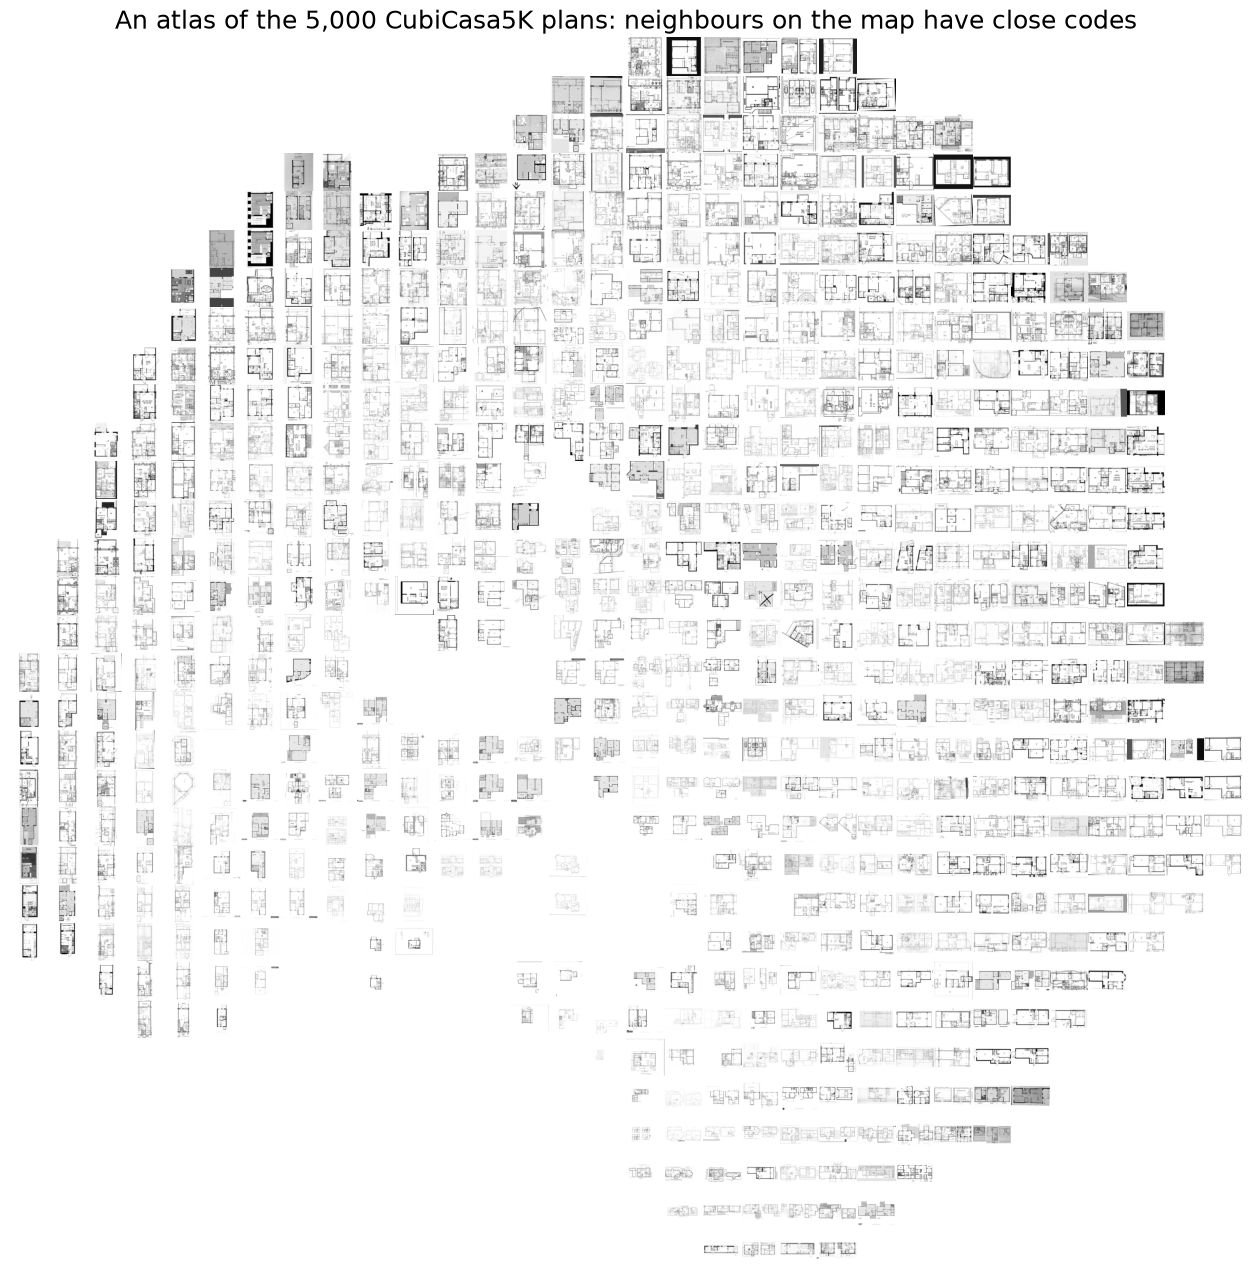

In [20]:
#the 5,000 codes on a 2D map (UMAP, as on Day 3), scaled to 0-1 so we can cut it into a grid
atlas_xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_all.numpy())
atlas_xy = (atlas_xy - atlas_xy.min(axis=0)) / (atlas_xy.max(axis=0) - atlas_xy.min(axis=0))

GRID = 32   #32 x 32 cells; every cell that has plans shows the one closest to its centre
fig, ax = plt.subplots(figsize=(16, 16))
for row in range(GRID):
    for col in range(GRID):
        centre = np.array([(col + 0.5) / GRID, (row + 0.5) / GRID])
        distances = np.linalg.norm(atlas_xy - centre, axis=1)
        nearest = distances.argmin()
        if distances[nearest] < 0.7 / GRID:
            plan = 1 - X_all[nearest, 0].numpy()   #dark lines on white, like a printed plan
            ax.imshow(plan, cmap="gray", vmin=0, vmax=1,
                      extent=(col / GRID, (col + 1) / GRID, row / GRID, (row + 1) / GRID))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("An atlas of the 5,000 CubiCasa5K plans: neighbours on the map have close codes", fontsize=18)
save_fig("08_plan_atlas")
plt.show()

The atlas shows what the codes have learned. On the left are the tall, narrow plans and on the right the wide ones, so the first thing the model sorts by is the proportion of the plan. At the top are the bold drawings, with thick black walls and grey fills, and at the bottom the small, very wide plans, often two buildings side by side. The faint scans sit together in the middle. None of this was given to the model: it found it only by learning to redraw the plans. It's also a picture of the limits: it groups plans by shape and by how they're drawn, not by how the rooms are used.

# 5. Saving the model for Tuesday's server
Like section 9 of the class notebook. For similarity search the server needs more than the model: it also needs the codes of the whole collection, to compare a new plan with.

| File | What's in it |
|---|---|
| `floorplan_ae.onnx` | the model, with two outputs: the code (for the search) and the reconstruction |
| `floorplan_ae_config.json` | the image size, the preprocessing steps, the code size and the setup |
| `collection_codes.npy` | the code of each of the 5,000 plans |
| `collection_ids.json` | which plan each code belongs to |
| `examples/*.png` | four plans to try on the server page |

The `.onnx`, `.pt` and `.npy` files go to Hugging Face, not to GitHub (they're in `.gitignore`).

In [21]:
class CodeAndReconstruction(nn.Module):
    # Wraps the AE so the ONNX file returns both the code and the reconstruction
    def __init__(self, ae):
        super().__init__()
        self.ae = ae

    def forward(self, x):
        code = self.ae.encoder(x)
        return code, self.ae.decoder(code)


import logging

#the ONNX exporter warns that torchvision isn't installed: we don't need it
logging.getLogger("torch.onnx").setLevel(logging.ERROR)

best = best.cpu().eval()
export_model = CodeAndReconstruction(best).eval()
torch.save(best.state_dict(), MODEL_DIR / "floorplan_ae.pt")
torch.onnx.export(export_model, (X_test[:1],), MODEL_APP_DIR / "floorplan_ae.onnx",
                  input_names=["image"], output_names=["code", "reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)

np.save(MODEL_APP_DIR / "collection_codes.npy", encode(best, X_all).numpy().astype(np.float32))
(MODEL_APP_DIR / "collection_ids.json").write_text(json.dumps(plan_ids.tolist()))

config = {
    "architecture": best_name,
    "latent_dim": int(codes_all.shape[1]),
    "image_size": IMAGE_SIZE,
    "preprocessing": "greyscale, invert (walls bright, background dark), pad to a square with black, "
                     "resize to 128x128 (Lanczos), pixels scaled to 0-1",
    "similarity": "Euclidean distance between codes; smaller = more similar",
    "collection": "CubiCasa5K, all 5,000 plans (train + validation + test)",
    "test_retrieval_top1": round(float(comparison.set_index("setup").loc[best_name, "retrieval top-1 (test)"]), 3),
}
(MODEL_APP_DIR / "floorplan_ae_config.json").write_text(json.dumps(config, indent=2))

for q in [0, 50, 120, 250]:
    plt.imsave(MODEL_APP_DIR / "examples" / f"plan_{ids_test[q].replace('/', '_')}.png",
               1 - X_test[q].squeeze().numpy(), cmap="gray", vmin=0, vmax=1)

for path in sorted(MODEL_APP_DIR.rglob("*.*")):
    print(f"{str(path):55s} {path.stat().st_size / 1024:9.1f} KB")

../model_app/atlas_v2_xy.npy                                 39.2 KB
../model_app/collection_codes.npy                          2500.1 KB
../model_app/collection_codes_v2.npy                       2500.1 KB
../model_app/collection_ids.json                            154.2 KB
../model_app/examples/plan_high_quality_architectural_1191.png      11.1 KB
../model_app/examples/plan_high_quality_architectural_1966.png       9.0 KB
../model_app/examples/plan_high_quality_architectural_20022.png       9.2 KB
../model_app/examples/plan_high_quality_architectural_435.png       7.4 KB
../model_app/floorplan_ae.onnx                             4615.6 KB
../model_app/floorplan_ae_config.json                         0.4 KB
../model_app/floorplan_ae_v2.onnx                          4615.6 KB
../model_app/floorplan_ae_v2_config.json                      0.6 KB


In [22]:
# Check: ONNX Runtime gives the same codes and the same errors as PyTorch
import onnxruntime as ort

session = ort.InferenceSession(MODEL_APP_DIR / "floorplan_ae.onnx")
batch = X_test[:5].numpy()
onnx_code, onnx_rec = session.run(None, {"image": batch})
onnx_scores = ((onnx_rec - batch) ** 2).mean(axis=(1, 2, 3))

with torch.no_grad():
    torch_code, torch_rec = export_model(X_test[:5])
torch_scores = ((torch_rec - X_test[:5]) ** 2).mean(dim=(1, 2, 3)).numpy()

print("PyTorch errors:     ", torch_scores.round(5))
print("ONNX Runtime errors:", onnx_scores.round(5))
print("same errors:", np.allclose(torch_scores, onnx_scores, atol=1e-6))
print("same codes: ", np.allclose(torch_code.numpy(), onnx_code, atol=1e-4))

PyTorch errors:      [0.00818 0.00477 0.00543 0.01882 0.00265]
ONNX Runtime errors: [0.00818 0.00477 0.00543 0.01882 0.00265]
same errors: True
same codes:  True


ONNX Runtime gives exactly the same errors and codes as PyTorch, so the server will answer like the notebook.

Everything that goes to Hugging Face is copied into `models/`, next to the model card: the model, the collection, the config, the examples and the three figures the card shows.

In [23]:
#one folder for Hugging Face: the model card (models/README.md) and everything it needs
import shutil

for name in ["floorplan_ae.onnx", "floorplan_ae_config.json", "collection_codes.npy", "collection_ids.json"]:
    shutil.copy(MODEL_APP_DIR / name, MODEL_DIR / name)
shutil.copytree(MODEL_APP_DIR / "examples", MODEL_DIR / "examples", dirs_exist_ok=True)

(MODEL_DIR / "figures").mkdir(exist_ok=True)
for name in ["02_training_curves.png", "03_reconstructions.png", "04_similarity_search.png",
             "05_baselines.png", "06_failures_by_ink.png", "08_plan_atlas.png"]:
    shutil.copy(FIG_DIR / name, MODEL_DIR / "figures" / name)

for path in sorted(MODEL_DIR.rglob("*.*")):
    print(f"{str(path):55s} {path.stat().st_size / 1024:9.1f} KB")

../models/README.md                                           7.2 KB
../models/atlas_v2_xy.npy                                    39.2 KB
../models/collection_codes.npy                             2500.1 KB
../models/collection_codes_v2.npy                          2500.1 KB
../models/collection_ids.json                               154.2 KB
../models/examples/plan_high_quality_architectural_1191.png      11.1 KB
../models/examples/plan_high_quality_architectural_1966.png       9.0 KB
../models/examples/plan_high_quality_architectural_20022.png       9.2 KB
../models/examples/plan_high_quality_architectural_435.png       7.4 KB
../models/figures/02_training_curves.png                    110.4 KB
../models/figures/03_reconstructions.png                    565.8 KB
../models/figures/04_similarity_search.png                  565.8 KB
../models/figures/05_baselines.png                           35.4 KB
../models/figures/06_failures_by_ink.png                     38.4 KB
../models/figures/

# 6. Version 2: compare the layout, not the drawing style

The atlas and the failures say the same thing: after the proportions, the second thing our codes follow is **how a plan is drawn**: thick or thin lines, grey fills, faint scans. For an architect that's the wrong kind of similarity. A plan should find plans with a similar layout, whatever pen drew them.

Chloe's notebook gave us the tools to measure this. She described every plan with four rendering features (how much is drawn, contrast, edge strength and sharpness) and measured the error only on the drawn pixels. We use her features to check how much drawing style is in our codes, then try to take it out by cleaning every plan before the model sees it.

### How much style is in the v1 codes?
For each feature we compare a plan with its 5 nearest plans and with 5 random plans. 100% means the neighbours are as different as random plans, so the search ignores that feature. A low value means the neighbours are alike in that feature, so the search follows it.

In [24]:
#Chloe's rendering features, measured on every plan as it is drawn (walls bright, 0-1)
def style_features(X):
    x = X[:, 0].numpy()
    dx = np.abs(np.diff(x, axis=2)).mean(axis=(1, 2))
    dy = np.abs(np.diff(x, axis=1)).mean(axis=(1, 2))
    laplacian = x[:, 1:-1, :-2] + x[:, 1:-1, 2:] + x[:, :-2, 1:-1] + x[:, 2:, 1:-1] - 4 * x[:, 1:-1, 1:-1]
    return pd.DataFrame({
        "how much is drawn": (x > 0.1).mean(axis=(1, 2)),
        "contrast": x.std(axis=(1, 2)),
        "edge strength": (dx + dy) / 2,
        "sharpness": laplacian.var(axis=(1, 2)),
        "grey fills": ((x > 0.15) & (x < 0.6)).mean(axis=(1, 2)),
    })


def style_in_codes(codes, features, k=5):
    #for each feature: how different are a plan and its 5 nearest plans, compared with 5 random plans?
    #100% = the neighbours are as different as random plans (the code ignores it), 0% = identical
    neighbours = torch.cdist(codes, codes).topk(k + 1, largest=False).indices[:, 1:].numpy()
    random_plans = np.random.default_rng(RANDOM_STATE).integers(0, len(codes), (len(codes), k))
    ratios = {}
    for name in features.columns:
        v = features[name].to_numpy()
        ratios[name] = np.abs(v[:, None] - v[neighbours]).mean() / np.abs(v[:, None] - v[random_plans]).mean()
    return pd.Series(ratios)


features_all = style_features(X_all)
style_v1 = style_in_codes(codes_all, features_all)
style_v1.to_frame("neighbours vs random (v1)").style.format("{:.0%}")

,neighbours vs random (v1)
how much is drawn,54%
contrast,64%
edge strength,62%
sharpness,69%
grey fills,62%


The neighbours share the drawing style much more than random plans do. In how much is drawn they differ only about half as much as random plans (54%), and in contrast, edges, sharpness and grey fills about two thirds as much (62% to 69%). So a bold drawing mostly finds bold drawings and a faint scan finds faint scans, whatever the layout.

### Cleaning the drawings
Every plan is reduced to its lines, the same way for every drawing:
1. a minimum and then a maximum filter of 5 x 5 px (an "opening") erase every line thinner than about 5 px and keep only the wide parts: grey fills, grey paper, dark borders;
2. the plan minus these wide parts leaves only the lines;
3. the lines of each plan are scaled by its own strong lines (90th percentile) and cut at 0.35, so a faint scan and a bold drawing come out equally bright.

The server has to do exactly the same to every upload.

share of line pixels: 0.066 as drawn, 0.119 cleaned
how much the plans differ in amount drawn (std / mean): 0.56 as drawn, 0.38 cleaned


Figure saved to ../figures/09_cleaning.png


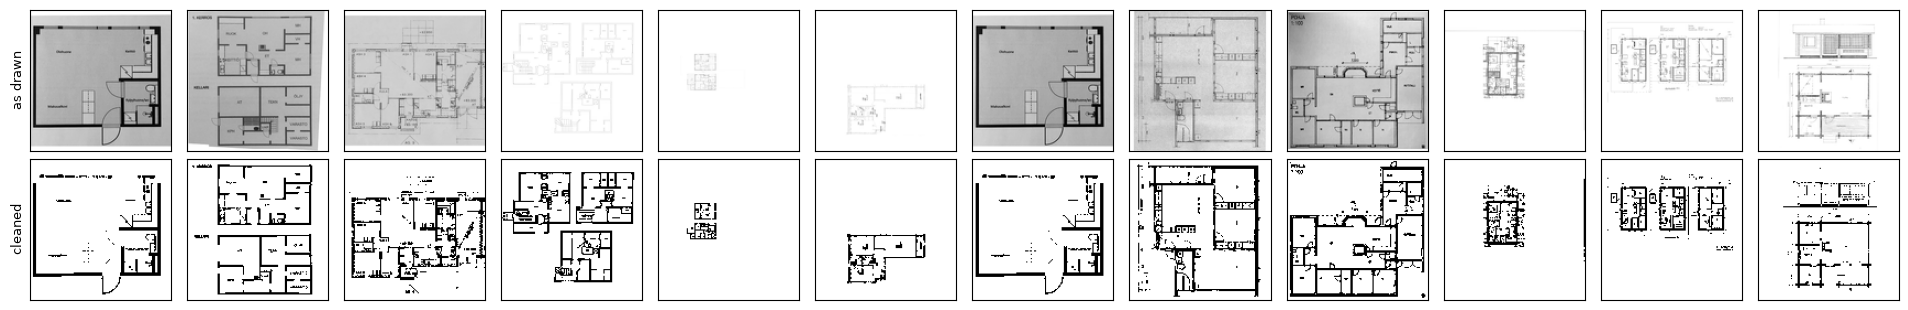

In [25]:
def clean_plan(plan):
    #plan: 128x128 uint8, walls bright. Keep only the lines, the same way for every drawing
    image = Image.fromarray(plan)
    wide = image.filter(ImageFilter.MinFilter(5)).filter(ImageFilter.MaxFilter(5))   #only what is wider than ~4 px: fills, grey paper, dark borders
    lines = np.asarray(image, np.float32) - np.asarray(wide, np.float32)             #the plan minus the wide parts = the lines
    strong = lines[lines > 8]
    if strong.size < 20:                                                             #nothing drawn
        return np.zeros_like(plan)
    return ((lines / np.percentile(strong, 90)) > 0.35).astype(np.uint8) * 255      #scaled by its own lines: faint and bold come out the same


from PIL import ImageFilter

cleaned = np.stack([clean_plan(plan) for plan in images])
X2_all = torch.from_numpy(cleaned).float().div(255).unsqueeze(1)
X2_train = X2_all[plan_splits == "train"]
X2_val = X2_all[plan_splits == "val"]
X2_test = X2_all[plan_splits == "test"]
print(f"share of line pixels: {X_all.mean():.3f} as drawn, {X2_all.mean():.3f} cleaned")
print(f"how much the plans differ in amount drawn (std / mean): {X_all.mean(dim=(1, 2, 3)).std() / X_all.mean():.2f} as drawn, "
      f"{X2_all.mean(dim=(1, 2, 3)).std() / X2_all.mean():.2f} cleaned")

#the plans with the most grey fill, the faintest, the boldest, and the first three
grey_order = features_all["grey fills"].to_numpy().argsort()
ink_order = features_all["how much is drawn"].to_numpy().argsort()
picks = list(grey_order[-3:]) + list(ink_order[:3]) + list(ink_order[-3:]) + [0, 1, 2]
show_images([X_all[picks], X2_all[picks]], row_labels=["as drawn", "cleaned"])
save_fig("09_cleaning")
plt.show()

The grey fills, the grey paper and the dark borders are gone (first three plans), and the faint scans (next three) now have lines as bright as the bold drawings. Every plan becomes the same kind of black and white line drawing: the share of line pixels goes from 6.6% to 11.9%, and the amount drawn varies much less from plan to plan (0.56 to 0.38).

The cleaning has limits. Walls thicker than about 5 px count as "wide" and partly disappear, so the boldest drawings lose some walls. And small drawings stay small: at 128 px we can't crop them to fill the square without blurring them into blocks. Both would be better done on the full-size images, before the resize.

### Training setup C on the cleaned plans
Same architecture, split, seed, epochs and loss (BCE) as setup C. Only the input changes. The retrieval test is the same too, with one difference that makes it harder: the shifted, noisy copy is made from the plan as drawn and then cleaned, like a plan uploaded to the server.

In [26]:
#setup C again (conv, code 128), same split, seed, epochs and loss: only the input changes
model_v2, history_v2, time_v2 = train_autoencoder(ConvAE(latent_dim=128), X2_train, X2_val, epochs=EPOCHS, verbose=False)


def retrieval_cleaned(model, X_test_drawn, X_test_cleaned):
    #the shifted, noisy copy is made from the plan AS DRAWN and then cleaned, like an upload on the server
    shifted = perturb(X_test_drawn)
    shifted_cleaned = np.stack([clean_plan((s[0].numpy() * 255).round().astype(np.uint8)) for s in shifted])
    query_codes = encode(model, torch.from_numpy(shifted_cleaned).float().div(255).unsqueeze(1))
    return (torch.cdist(query_codes, encode(model, X_test_cleaned)).argmin(dim=1) == torch.arange(len(X_test_cleaned))).numpy()


def foreground_mse(model, X):
    #Chloe's idea: the error on the drawn pixels only, where a blank page can't cheat
    error = (reconstruct(model, X) - X) ** 2
    return error[X > 0.5].mean().item()


found_v2 = retrieval_cleaned(model_v2, X_test, X2_test)
version_table = pd.DataFrame({
    "input": ["plans as drawn", "cleaned plans"],
    "test MSE": [reconstruction_error(best, X_test).mean().item(), reconstruction_error(model_v2, X2_test).mean().item()],
    "blank page MSE": [(X_test ** 2).mean().item(), (X2_test ** 2).mean().item()],
    "foreground MSE": [foreground_mse(best, X_test), foreground_mse(model_v2, X2_test)],
    "retrieval top-1 (test)": [found.mean(), found_v2.mean()],
}, index=["v1 (Monday)", "v2"])

#and by how much is drawn, like in section 4
by_ink_v2 = pd.Series(found_v2).groupby(ink_quarter, observed=True).mean()
print(pd.DataFrame({"v1": by_ink, "v2": by_ink_v2}).map("{:.0%}".format))
version_table

trained in 175 s


              v1   v2
least drawn  28%  77%
2nd quarter  66%  97%
3rd quarter  84%  90%
most drawn   98%  81%


,input,test MSE,blank page MSE,foreground MSE,retrieval top-1 (test)
v1 (Monday),plans as drawn,0.0131,0.0300,0.1714,0.6900
v2,cleaned plans,0.0677,0.1137,0.3849,0.8625


- v2 finds the original of a shifted copy in **86%** of the test plans, against 69% for v1, with a harder test (the copy is cleaned after the shift and the noise, like an upload).
- The faint plans gain the most: on the quarter with the fewest lines from 28% to 77%. The boldest quarter loses (98% to 81%), because the cleaning takes away part of their thick walls. The search no longer works only on bold drawings: the four quarters are now between 77% and 97%.
- The errors can't be compared between the two lines. The cleaned plans are pure black and white and have almost twice as many line pixels, so every error is bigger. Against its own blank page v2 is 40% lower (0.0677 against 0.1137), v1 57%. On the drawn pixels only (Chloe's foreground MSE) v2 is worse (0.385 against 0.171): it redraws the cleaned lines less sharply. For the search that matters less, because the search uses the code, not the redrawing.

### Is there less style in the v2 codes?

Figure saved to ../figures/10_style_in_codes.png


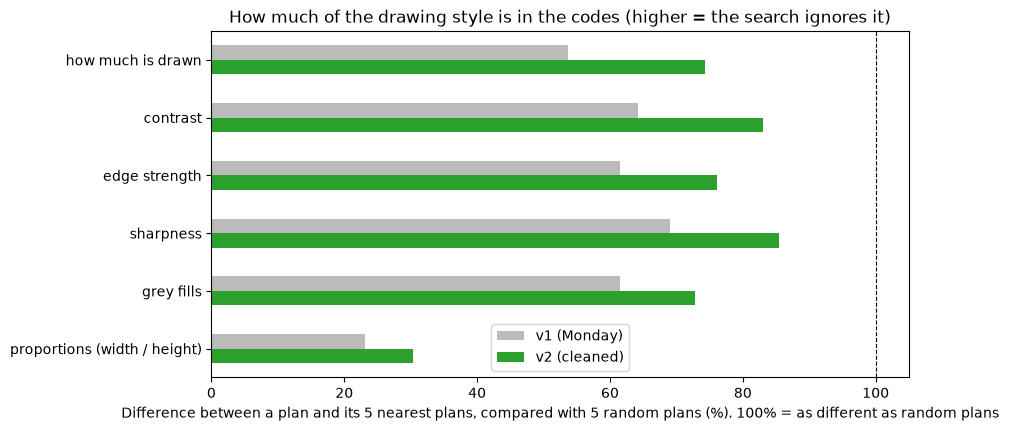

,v1 (Monday),v2 (cleaned)
how much is drawn,54%,74%
contrast,64%,83%
edge strength,62%,76%
sharpness,69%,85%
grey fills,62%,73%
proportions (width / height),23%,30%


In [27]:
codes_v2_all = encode(model_v2, X2_all)
features_all["proportions (width / height)"] = np.log((X2_all[:, 0] > 0.5).any(dim=1).sum(dim=1).clamp(min=1).numpy()
                                                      / (X2_all[:, 0] > 0.5).any(dim=2).sum(dim=1).clamp(min=1).numpy())
style_table = pd.DataFrame({"v1 (Monday)": style_in_codes(codes_all, features_all),
                            "v2 (cleaned)": style_in_codes(codes_v2_all, features_all)})

ax = (style_table * 100).plot.barh(figsize=(9, 4.5), color=["#bbbbbb", "#2ca02c"])
ax.axvline(100, color="black", lw=0.8, ls="--")
ax.invert_yaxis()
ax.set_xlabel("Difference between a plan and its 5 nearest plans, compared with 5 random plans (%). 100% = as different as random plans")
ax.set_title("How much of the drawing style is in the codes (higher = the search ignores it)")
save_fig("10_style_in_codes")
plt.show()
style_table.style.format("{:.0%}")

With v2 every style feature moves towards 100%: the neighbours now differ 74% as much as random plans in how much is drawn (54% with v1), 83% in contrast (64%), 76% in edge strength (62%), 85% in sharpness (69%) and 73% in grey fills (62%). The proportions stay low (30%, 23% with v1), so the neighbours still have the same shape.

v2 still looks at the shape, and much less at the pen. The style isn't gone completely (it isn't 100%): line thickness and the size of the drawing on the page are still in the cleaned images.

### The same four searches with v2

query 0: distances 91.80-98.96
query 50: distances 123.25-131.81
query 120: distances 98.05-103.82
query 250: distances 82.30-88.45


Figure saved to ../figures/11_similarity_search_v2.png


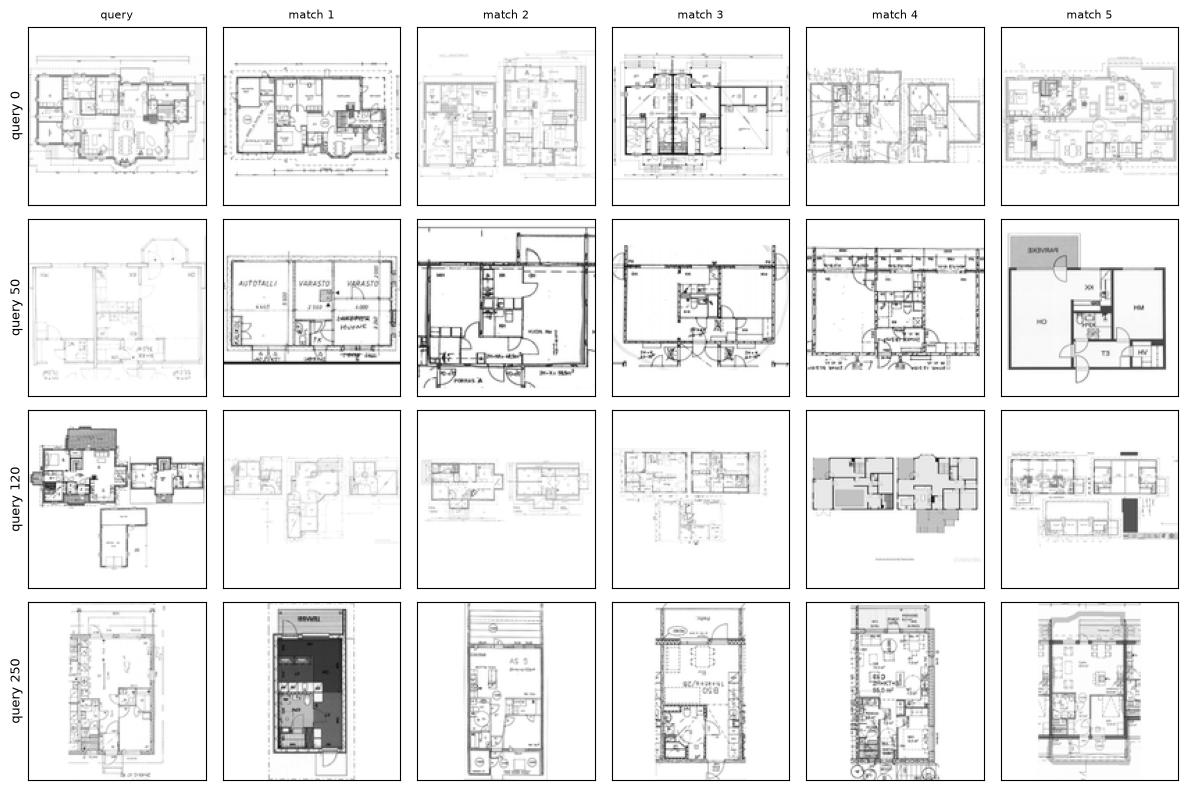

In [28]:
#the same four queries as in section 4, now with v2. We show the plans as drawn, so the style is visible
rows, labels = [], []
for q in [0, 50, 120, 250]:
    query_index = test_positions[q]
    idx, dists = most_similar(codes_v2_all[query_index], codes_v2_all, exclude=query_index)
    rows.append(torch.cat([X_all[query_index:query_index + 1], X_all[idx]]))
    labels.append(f"query {q}")
    print(f"query {q}: distances {dists.min():.2f}-{dists.max():.2f}")

show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 6)], size=2.0)
save_fig("11_similarity_search_v2")
plt.show()

Compared with section 4, the matches now mix drawing styles:
- the faint scan of query 50 finds bold drawings with the same layout: a wide rectangle with a small core of bathrooms in the middle;
- the narrow flat of query 250 finds narrow flats with the balcony at one end and the bathroom at the other, one of them with grey fills;
- query 120, three separate buildings, finds plans with two or three volumes, faint and bold;
- query 0, a wide house with wings, finds wide houses with wings.

The distances are bigger than in v1 (82 to 132) because the v2 codes have another scale. Distances can only be compared within one version.

### The atlas with v2

Figure saved to ../figures/12_plan_atlas_v2.png


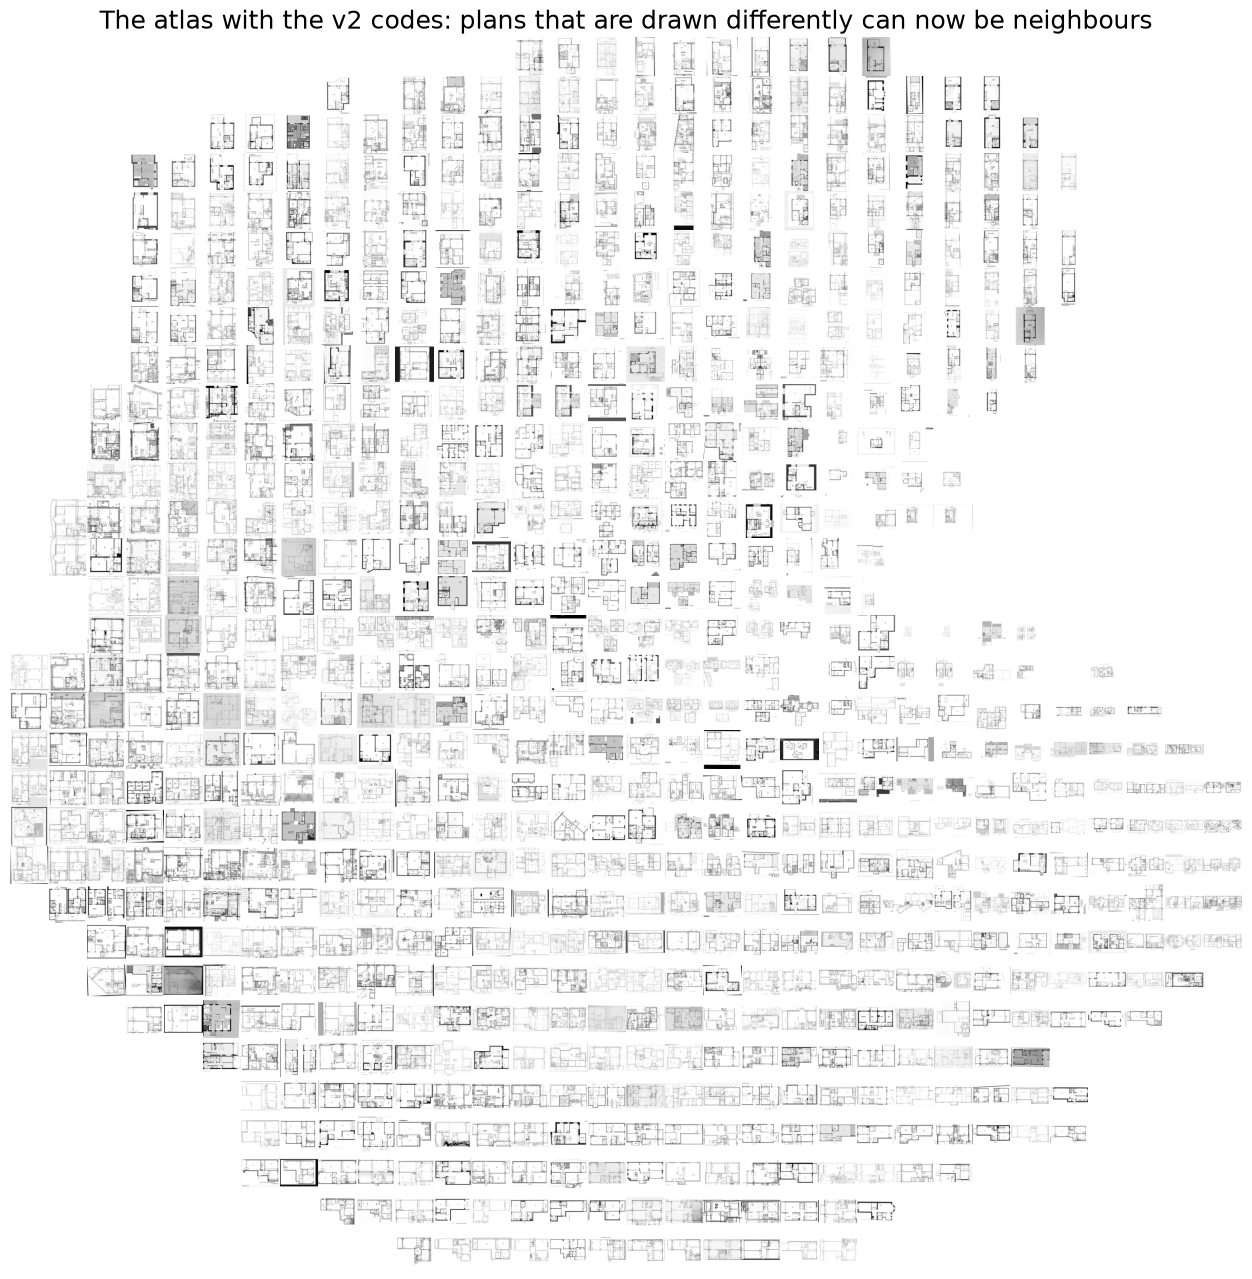

In [29]:
#the atlas again, with the v2 codes, drawn with the plans as they are drawn
atlas_v2_xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_v2_all.numpy())
atlas_v2_xy = (atlas_v2_xy - atlas_v2_xy.min(axis=0)) / (atlas_v2_xy.max(axis=0) - atlas_v2_xy.min(axis=0))

fig, ax = plt.subplots(figsize=(16, 16))
for row in range(GRID):
    for col in range(GRID):
        centre = np.array([(col + 0.5) / GRID, (row + 0.5) / GRID])
        distances = np.linalg.norm(atlas_v2_xy - centre, axis=1)
        nearest = distances.argmin()
        if distances[nearest] < 0.7 / GRID:
            ax.imshow(1 - X_all[nearest, 0].numpy(), cmap="gray", vmin=0, vmax=1,
                      extent=(col / GRID, (col + 1) / GRID, row / GRID, (row + 1) / GRID))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("The atlas with the v2 codes: plans that are drawn differently can now be neighbours", fontsize=18)
save_fig("12_plan_atlas_v2")
plt.show()

On the v2 atlas the bold drawings, the grey fills and the faint scans are mixed all over the map, while on the v1 atlas they had their own regions (the bold ones at the top). What orders the map now is the shape: tall, narrow plans at the top, wide ones at the bottom and the small drawings on the right. That's the order we want for an architect: plans that are alike as plans, not as drawings.

### Saving v2 for the server
v2 is saved next to v1 with new names (`floorplan_ae_v2.onnx`, `floorplan_ae_v2_config.json`, `collection_codes_v2.npy`), so Monday's files stay as they were. We also keep the map positions of the v2 atlas (`atlas_v2_xy.npy`) for the app.

In [30]:
#v2 for the server: the same two outputs (code and reconstruction), new file names so v1 stays as it was
model_v2 = model_v2.cpu().eval()
torch.save(model_v2.state_dict(), MODEL_DIR / "floorplan_ae_v2.pt")
torch.onnx.export(CodeAndReconstruction(model_v2).eval(), (X2_test[:1],), MODEL_APP_DIR / "floorplan_ae_v2.onnx",
                  input_names=["image"], output_names=["code", "reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)
np.save(MODEL_APP_DIR / "collection_codes_v2.npy", codes_v2_all.numpy().astype(np.float32))
np.save(MODEL_APP_DIR / "atlas_v2_xy.npy", atlas_v2_xy.astype(np.float32))   #the map positions, for the app

config_v2 = dict(config, architecture="C (conv, code 128), trained on cleaned plans",
                 preprocessing=config["preprocessing"] + "; then cleaned: keep only lines thinner than 5 px "
                               "(plan minus its 5x5 opening), scale by the 90th percentile of its lines, threshold 0.35",
                 test_retrieval_top1=round(float(found_v2.mean()), 3))
(MODEL_APP_DIR / "floorplan_ae_v2_config.json").write_text(json.dumps(config_v2, indent=2))

#check the ONNX file like for v1
session_v2 = ort.InferenceSession(MODEL_APP_DIR / "floorplan_ae_v2.onnx")
onnx_code, _ = session_v2.run(None, {"image": X2_test[:5].numpy()})
print("same codes as PyTorch:", np.allclose(encode(model_v2, X2_test[:5]).numpy(), onnx_code, atol=1e-4))

for name in ["floorplan_ae_v2.onnx", "floorplan_ae_v2_config.json", "collection_codes_v2.npy", "atlas_v2_xy.npy"]:
    shutil.copy(MODEL_APP_DIR / name, MODEL_DIR / name)
for name in ["09_cleaning.png", "10_style_in_codes.png", "11_similarity_search_v2.png", "12_plan_atlas_v2.png"]:
    shutil.copy(FIG_DIR / name, MODEL_DIR / "figures" / name)
print("v2 saved in", MODEL_APP_DIR, "and", MODEL_DIR)

same codes as PyTorch: True
v2 saved in ../model_app and ../models


# 7. Conclusions and limitations

### What the output means for a user
You upload a floor plan and get the five plans, out of 5,000 real homes, whose overall layout is closest to yours.

### What we found
- A convolutional autoencoder with a code of 128 numbers works best: test MSE 0.0131 and 69% retrieval, against 47% with 32 numbers and 21% for the dense model.
- The search finds plans with the same footprint and proportions (narrow, wide, made of several buildings), about 3 times closer than a random plan.
- The autoencoder is worth it: on the same test the raw pixels find the original 4% of the time and PCA with 128 numbers 25%.
- It works on bold plans and fails on faint ones: 98% on the quarter with the most lines, 28% on the quarter with the fewest.
- On the atlas of the 5,000 plans the model sorts them first by proportion (narrow to wide), then by how they're drawn.
- Training with BCE instead of MSE was needed: with MSE the models only drew a blank page.
- Version 2 cleans every plan down to its lines before the model, with ideas from Chloe's notebook: her rendering features to measure the style, and the error on the drawn pixels. Retrieval goes from 69% to 86%, the faint plans from 28% to 77%, and the neighbours share much less of the drawing style. The server uses v2.

### Limitations
- At 128 px thin walls, doors and text blur or disappear, so the model compares the overall shape, not the details.
- Similar pixels aren't a similar use: two plans can look alike and have very different room programmes. We don't use the room annotations.
- The way a plan is drawn still matters, less in v2 than in v1: line thickness and the size of the drawing on the page still count, and the cleaning takes away part of the thickest walls (the boldest plans drop from 98% to 81%).
- Retrieval is 69%, not 100%: in about 3 out of 10 cases a slightly shifted copy doesn't find its own original first. All the setups were still improving at epoch 20.
- The plans are mostly Finnish homes, and the model isn't rotation-invariant: a plan turned by 90 degrees may not find its original.
- The dataset licence is [CC BY-NC 4.0](https://github.com/CubiCasa/CubiCasa5k/blob/master/LICENSE).